Saving results_for_colab.zip to results_for_colab.zip
Reading results from: /content/project_results/results_local


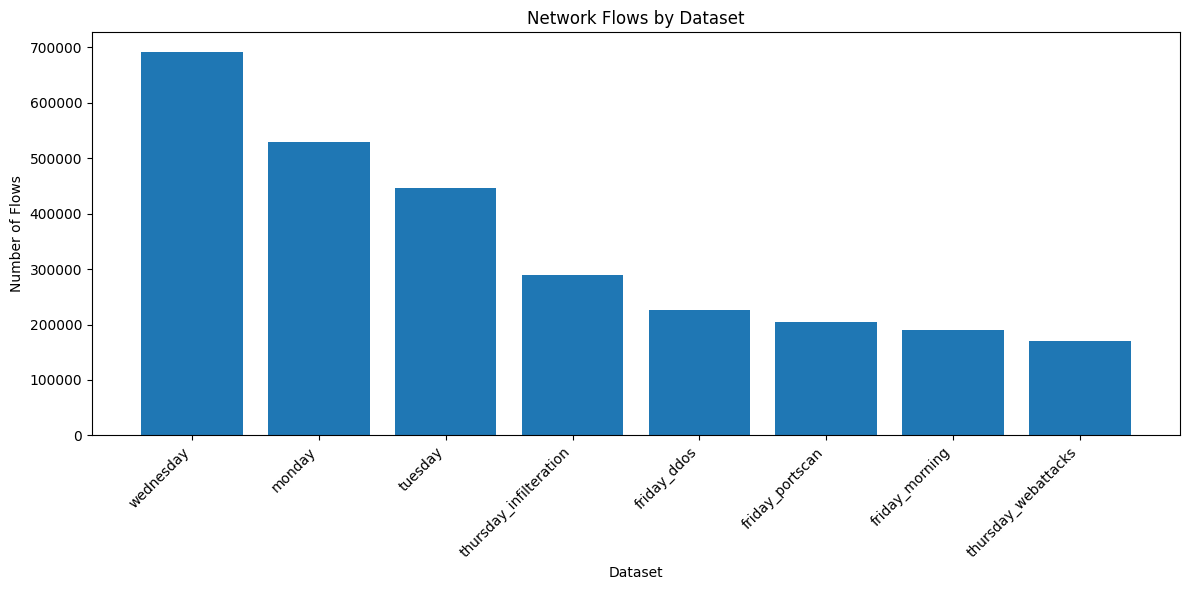

Saved: 01_dataset_flow_counts.png


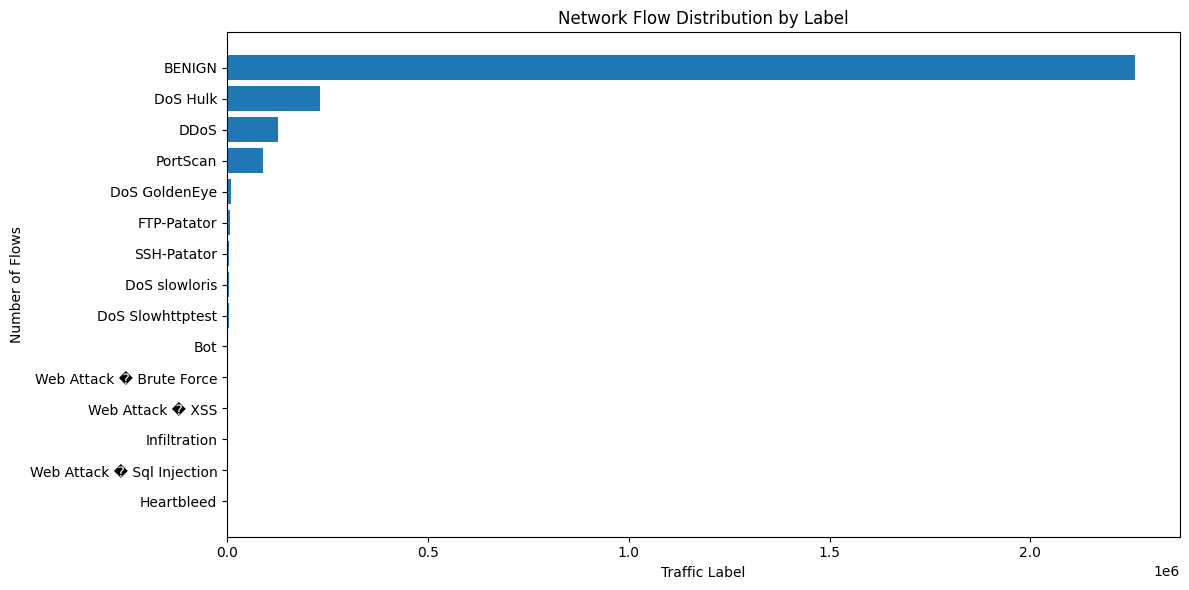

Saved: 02_attack_distribution.png


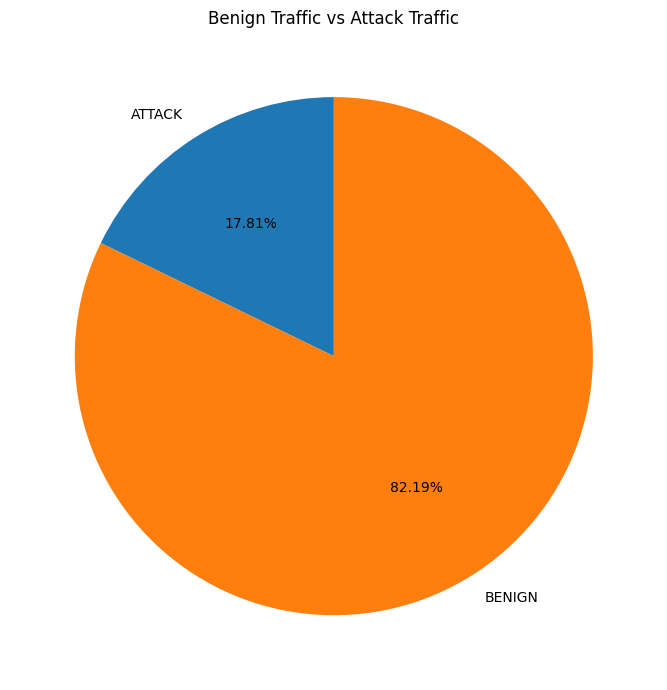

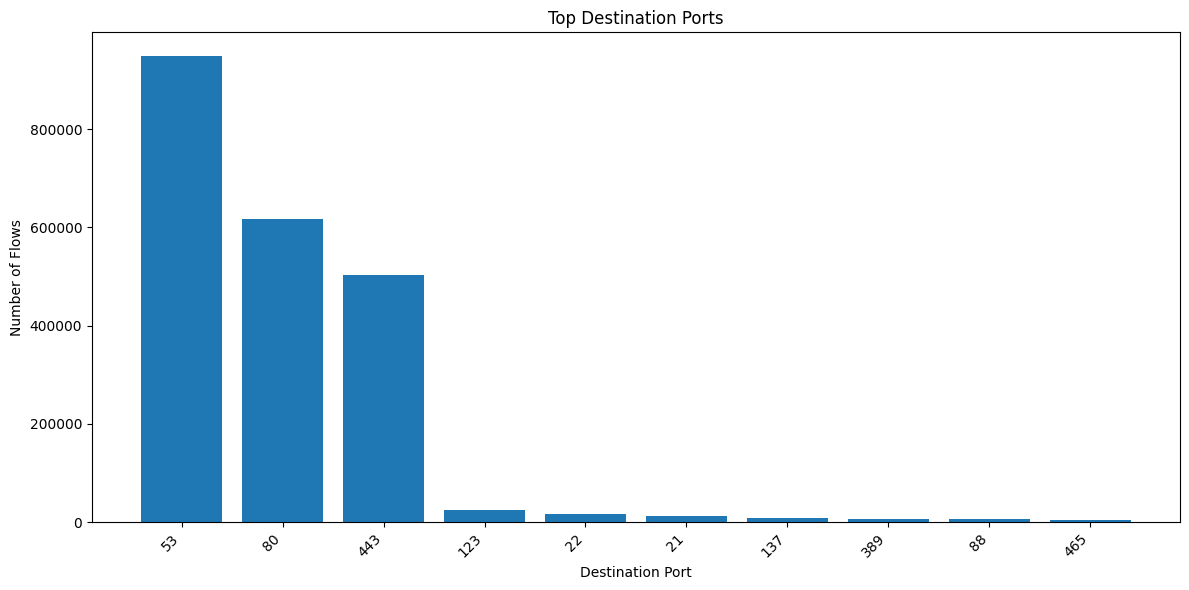

Saved: 04_top_destination_ports.png


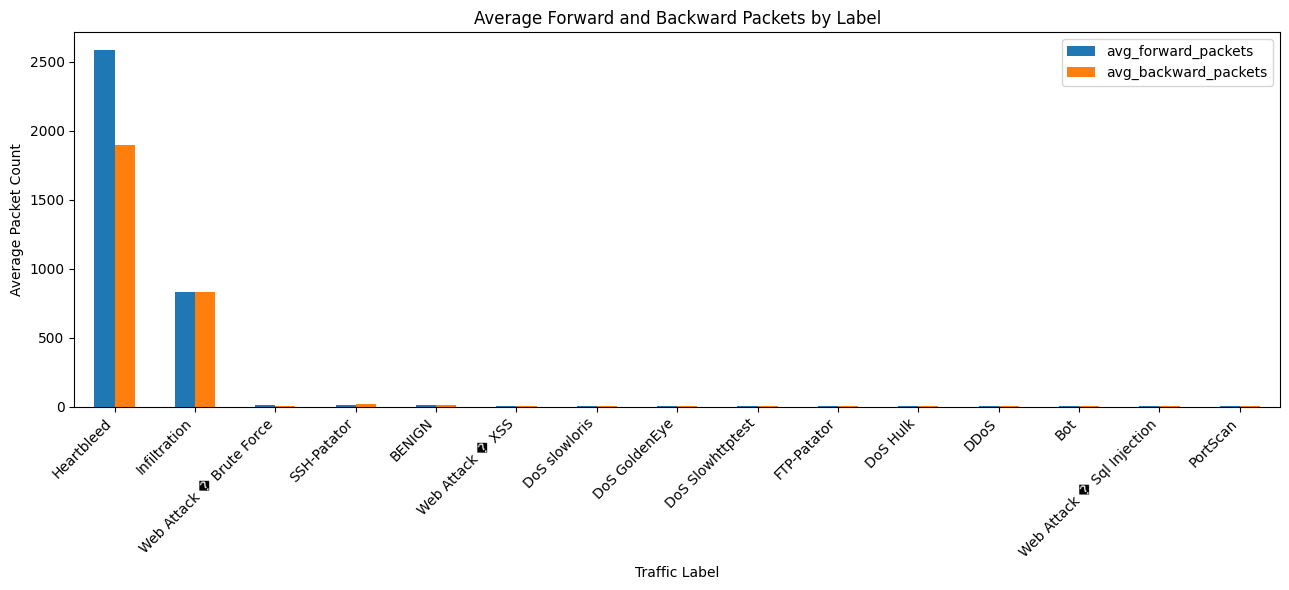

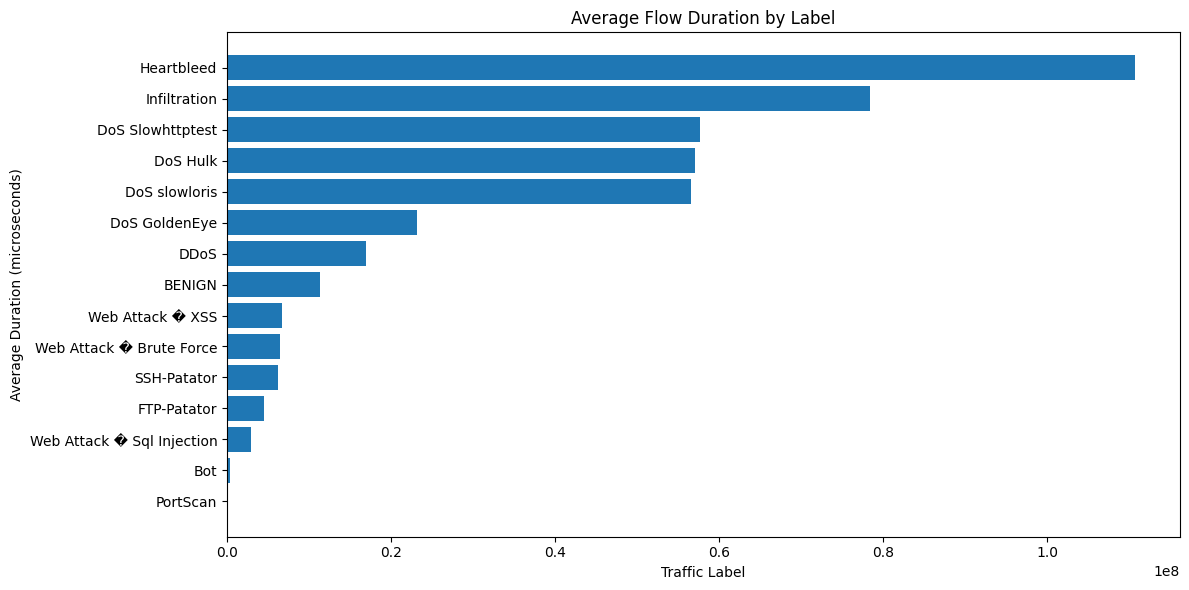

Saved: 06_average_flow_duration.png


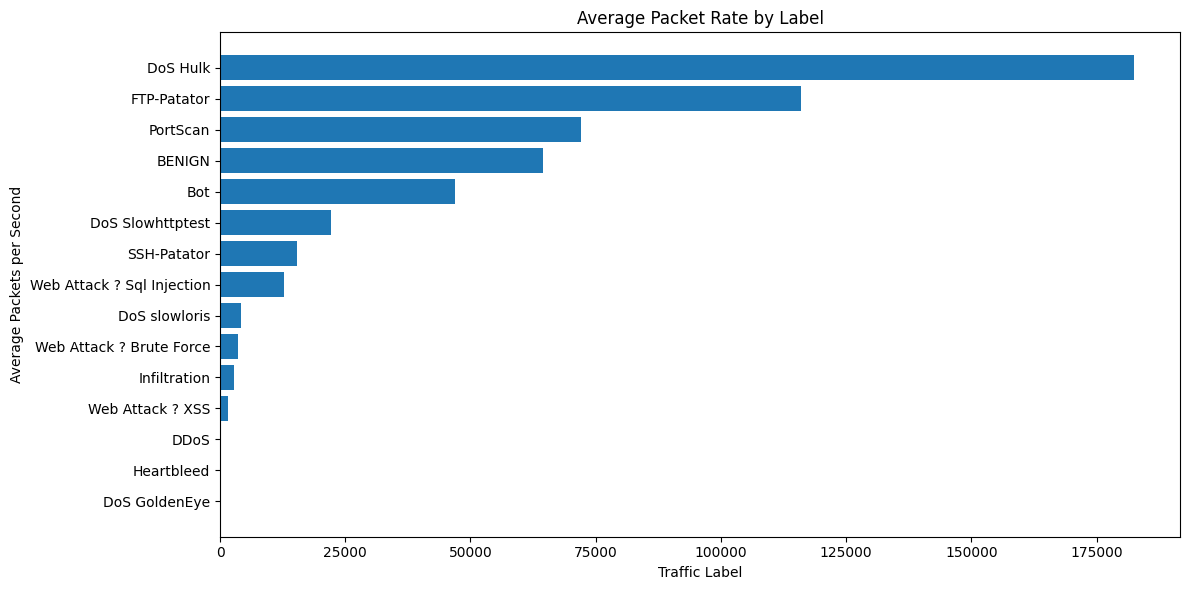

Saved: 07_packet_rate.png
Graphs created in: /content/project_graphs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import zipfile
import glob
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload your results_local.zip
uploaded = files.upload()
zip_name = next(iter(uploaded))

# Extract the ZIP
with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/project_results")

# Find the results_local directory
matches = glob.glob(
    "/content/project_results/**/results_local",
    recursive=True
)
if not matches:
    raise FileNotFoundError(
        "Could not find results_local. Check the ZIP folder structure."
    )

ROOT = matches[0]
OUT = "/content/project_graphs"
os.makedirs(OUT, exist_ok=True)

print("Reading results from:", ROOT)


def load_result(folder, columns):
    """Read a Hive result file, whether comma- or tab-separated."""
    folder_path = os.path.join(ROOT, folder)
    candidates = [
        p for p in glob.glob(folder_path + "/**/*", recursive=True)
        if os.path.isfile(p)
        and not os.path.basename(p).startswith(".")
        and os.path.basename(p) != "_SUCCESS"
    ]

    if not candidates:
        raise FileNotFoundError(f"No result file found in {folder}")

    path = candidates[0]
    df = pd.read_csv(
        path, sep=r"\t|,", engine="python",
        header=None, dtype=str, skipinitialspace=True
    )
    df = df.dropna(how="all").reset_index(drop=True)

    if len(df.columns) != len(columns):
        raise ValueError(
            f"{folder}: expected {len(columns)} columns, "
            f"found {len(df.columns)} in {path}"
        )

    df.columns = columns

    for col in columns:
        df[col] = df[col].astype(str).str.strip()

    return df


def save_bar(df, x, y, title, xlabel, ylabel, filename,
             horizontal=False, rotate=45):
    df[y] = pd.to_numeric(df[y], errors="coerce")
    df = df.dropna(subset=[y])

    if df.empty:
        print("Skipped empty chart:", title)
        return

    plt.figure(figsize=(12, 6))

    if horizontal:
        df = df.sort_values(y)
        plt.barh(df[x], df[y])
    else:
        df = df.sort_values(y, ascending=False)
        plt.bar(df[x], df[y])
        plt.xticks(rotation=rotate, ha="right")

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, filename), dpi=200)
    plt.show()
    plt.close()

    print("Saved:", filename)


# 1. Number of flows in each dataset
df = load_result("dataset_flow_counts", ["dataset", "flow_count"])
save_bar(
    df, "dataset", "flow_count",
    "Network Flows by Dataset",
    "Dataset", "Number of Flows",
    "01_dataset_flow_counts.png"
)

# 2. Attack distribution
df = load_result("attack_distribution", ["label", "flow_count"])
save_bar(
    df, "label", "flow_count",
    "Network Flow Distribution by Label",
    "Traffic Label", "Number of Flows",
    "02_attack_distribution.png",
    horizontal=True
)

# 3. Benign versus attack traffic
df = load_result(
    "benign_vs_attack",
    ["traffic_type", "flow_count", "percentage"]
)
df["flow_count"] = pd.to_numeric(df["flow_count"], errors="coerce")
df = df.dropna(subset=["flow_count"])

if not df.empty:
    plt.figure(figsize=(7, 7))
    plt.pie(
        df["flow_count"],
        labels=df["traffic_type"],
        autopct="%1.2f%%",
        startangle=90
    )
    plt.title("Benign Traffic vs Attack Traffic")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, "03_benign_vs_attack.png"), dpi=200)
    plt.show()
    plt.close()

# 4. Top destination ports
df = load_result(
    "top_destination_ports", ["destination_port", "flow_count"]
)
df["destination_port"] = df["destination_port"].astype(str)
save_bar(
    df, "destination_port", "flow_count",
    "Top Destination Ports",
    "Destination Port", "Number of Flows",
    "04_top_destination_ports.png"
)

# 5. Average forward and backward packets
df = load_result(
    "packet_behavior",
    ["label", "avg_forward_packets", "avg_backward_packets"]
)
for c in ["avg_forward_packets", "avg_backward_packets"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=[
    "avg_forward_packets", "avg_backward_packets"
])

if not df.empty:
    df = df.sort_values("avg_forward_packets", ascending=False)
    df.plot(
        x="label",
        y=["avg_forward_packets", "avg_backward_packets"],
        kind="bar",
        figsize=(13, 6)
    )
    plt.title("Average Forward and Backward Packets by Label")
    plt.xlabel("Traffic Label")
    plt.ylabel("Average Packet Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, "05_packet_behavior.png"), dpi=200)
    plt.show()
    plt.close()

# 6. Average flow duration
df = load_result(
    "average_flow_duration", ["label", "avg_flow_duration"]
)
save_bar(
    df, "label", "avg_flow_duration",
    "Average Flow Duration by Label",
    "Traffic Label", "Average Duration (microseconds)",
    "06_average_flow_duration.png",
    horizontal=True
)

# 7. Average packet rate
df = load_result(
    "packet_rate", ["label", "avg_packets_per_sec"]
)
save_bar(
    df, "label", "avg_packets_per_sec",
    "Average Packet Rate by Label",
    "Traffic Label", "Average Packets per Second",
    "07_packet_rate.png",
    horizontal=True
)

# Package all generated graphs into one ZIP
with zipfile.ZipFile("/content/project_graphs.zip", "w") as z:
    for name in os.listdir(OUT):
        z.write(os.path.join(OUT, name), arcname=name)

print("Graphs created in:", OUT)
files.download("/content/project_graphs.zip")
